In [4]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt

In [5]:
### Loading the summary data of each simulation 
machine_learning_results = pd.read_csv('../CafeteriaSimulation/results/machinelearning_results.csv')
fixed_simulation_results = pd.read_csv('../CafeteriaSimulation/results/fixedschedule_result.csv')
reactive_threshold_results = pd.read_csv('../CafeteriaSimulation/results/reactivethreshold_result.csv')

### Comparing each simulation outcomes

In [6]:
combined_table = pd.concat([machine_learning_results.assign(strategy="MLSimulation"), fixed_simulation_results.assign(strategy = "FixedScheduleSimulation"), reactive_threshold_results.assign(strategy = "ReactiveSimulation")])
combined_table.head(10)

,total_arrivals,leftover,waiting_end,mean_wait,p95_wait,max_queue,strategy
0,408,47,0,0.223039,2.0,25,MLSimulation
1,505,15,0,0.235644,2.0,20,MLSimulation
2,252,8,0,0.000000,0.0,0,MLSimulation
3,416,39,0,0.112981,1.0,14,MLSimulation
4,620,30,0,0.133871,1.0,15,MLSimulation
5,383,7,0,0.112272,1.0,13,MLSimulation
6,428,27,0,0.079439,1.0,10,MLSimulation
7,309,16,0,0.300971,3.0,24,MLSimulation
8,461,59,0,0.203905,2.0,16,MLSimulation
9,487,33,0,0.305955,2.7,22,MLSimulation


---
### Comparion 1: Students Still Waiting at Lunch Closing by Cooking Strategy

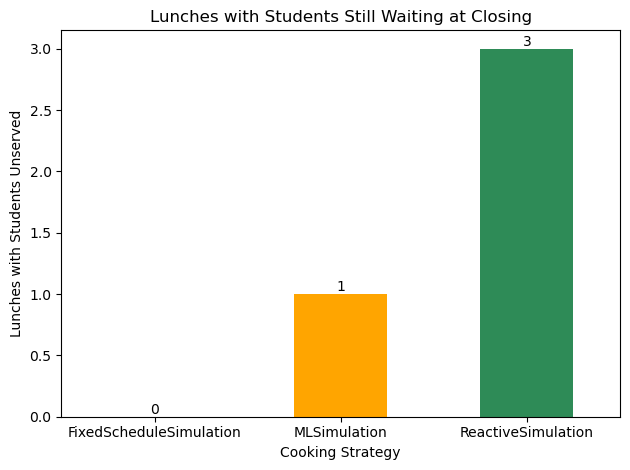

In [7]:
failed = (combined_table.assign(unserved=combined_table["waiting_end"].gt(0)).groupby("strategy")["unserved"].sum())
ax = failed.plot.bar(color=["steelblue", "orange", "seagreen"],rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.xlabel("Cooking Strategy")
plt.ylabel("Lunches with Students Unserved")
plt.title("Lunches with Students Still Waiting at Closing")
plt.tight_layout()
plt.savefig('../CafeteriaSimulation/comparisonsgraphs/studentswaiting.png')
plt.show()

### Comparison 2: Peak Student Queue by Category 

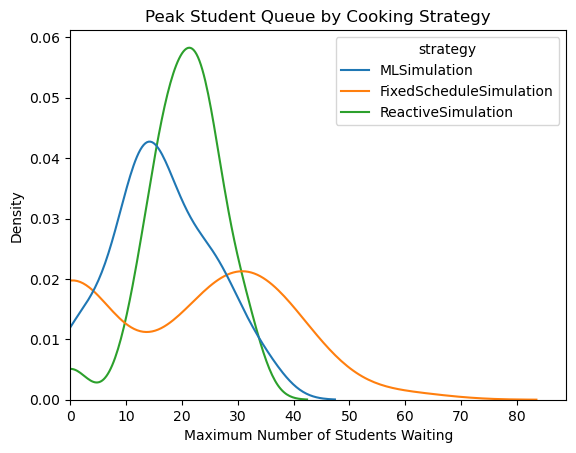

In [8]:
sns.kdeplot(data = combined_table, x = "max_queue", hue = "strategy",  common_norm = False)
plt.xlabel("Maximum Number of Students Waiting")
plt.ylabel("Density")
plt.title("Peak Student Queue by Cooking Strategy")
plt.xlim(left = 0)
plt.savefig('../CafeteriaSimulation/comparisonsgraphs/peakstudentqueue.png')
plt.show()

### Comparison 3: Leftover food count

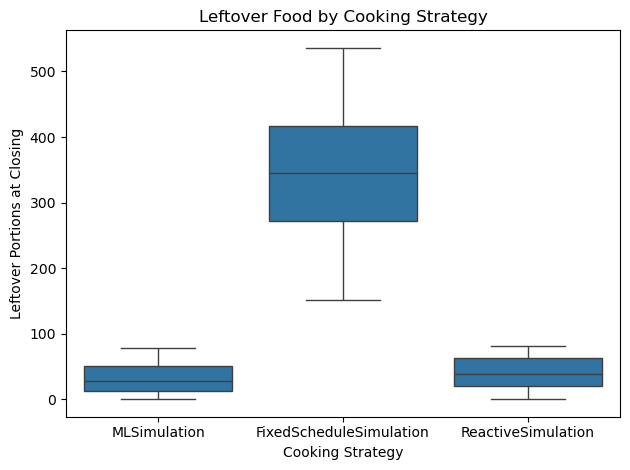

In [9]:
sns.boxplot(data=combined_table, x="strategy", y="leftover")

plt.xlabel("Cooking Strategy")
plt.ylabel("Leftover Portions at Closing")
plt.title("Leftover Food by Cooking Strategy")
plt.tight_layout()
plt.savefig('../CafeteriaSimulation/comparisonsgraphs/leftover.png')
plt.show()